In [2]:
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np

In [3]:
#Abrimos el fits de las estrellas
star_1b = fits.open('Star1_B.fits')[0]
star_1v = fits.open('Star1_V.fits')[0]
star_2b = fits.open('Star2_B.fits')[0]
star_2v = fits.open('Star2_V.fits')[0]

In [4]:
#Threshold, para cada estrella
threshold_1b = detect_threshold(star_1b.data, nsigma = 3)
threshold_1v = detect_threshold(star_1v.data, nsigma = 3)
threshold_2b = detect_threshold(star_2b.data, nsigma = 5)
threshold_2v = detect_threshold(star_2v.data, nsigma = 5)
#Detectamos fuentes
sour_1b = detect_sources(star_1b.data, threshold_1b, npixels=20)
sour_1v = detect_sources(star_1v.data, threshold_1v, npixels=20)
sour_2b = detect_sources(star_2b.data, threshold_2b, npixels=50)
sour_2v = detect_sources(star_2v.data, threshold_2v, npixels=50)

In [5]:
# Generamos un mapa de colores para cada fuente
cmap_sour_1b = sour_1b.make_cmap(seed=123)
cmap_sour_1v = sour_1v.make_cmap(seed=123)
cmap_sour_2b = sour_2b.make_cmap(seed=123)
cmap_sour_2v = sour_2v.make_cmap(seed=123)


In [6]:
print("HIP 6257 - B:", sour_1b.n_labels, "fuentes detectadas")
print("HIP 6257 - V:", sour_1v.n_labels, "fuentes detectadas")

print("HIP 115796 - B:", sour_2b.n_labels, "fuentes detectadas")
print("HIP 115796 - V:", sour_2v.n_labels, "fuentes detectadas")

HIP 6257 - B: 71 fuentes detectadas
HIP 6257 - V: 23 fuentes detectadas
HIP 115796 - B: 22 fuentes detectadas
HIP 115796 - V: 17 fuentes detectadas


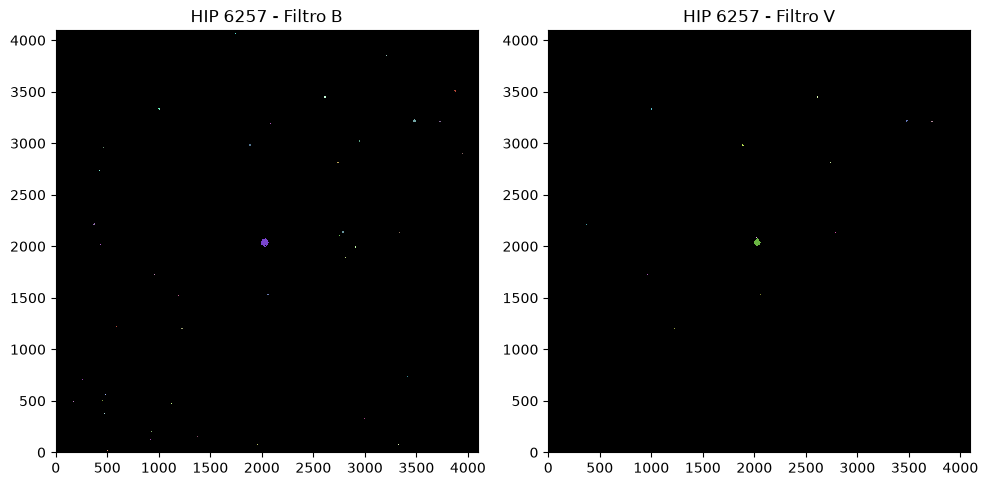

HIP 6257 - Filtro B:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 71
labels: [ 1  2  3  4  5 ... 67 68 69 70 71]
HIP 6257 - Filtro V:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 23
labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]


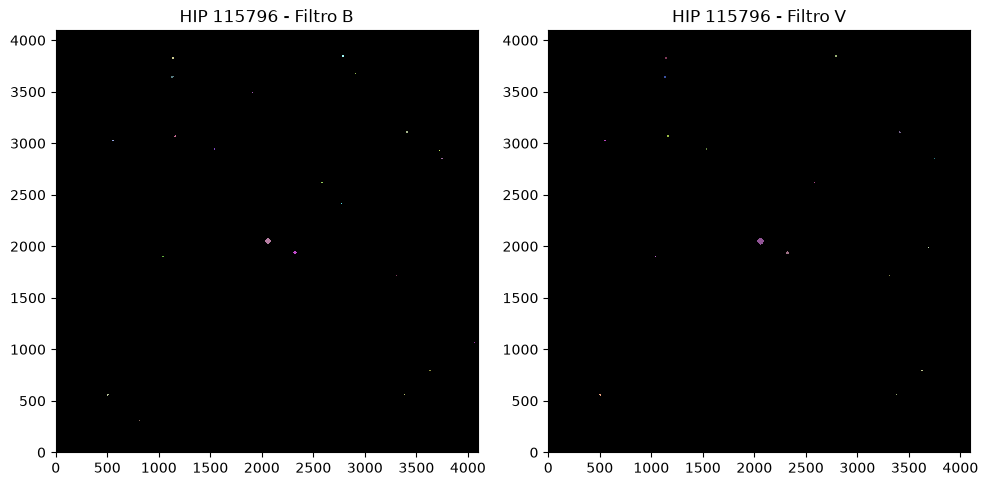

HIP 115796 - Filtro B:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 22
labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
HIP 115796 - Filtro V:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 17
labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


In [7]:
# HIP 6257
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sour_1b, origin='lower', cmap=cmap_sour_1b, interpolation='nearest')
ax[0].set_title('HIP 6257 - Filtro B')

ax[1].imshow(sour_1v, origin='lower', cmap=cmap_sour_1v, interpolation='nearest')
ax[1].set_title('HIP 6257 - Filtro V')

plt.tight_layout()
plt.show()

print("HIP 6257 - Filtro B:")
print(sour_1b)
print("HIP 6257 - Filtro V:")
print(sour_1v)


# HIP 115796
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sour_2b, origin='lower', cmap=cmap_sour_2b, interpolation='nearest')
ax[0].set_title('HIP 115796 - Filtro B')

ax[1].imshow(sour_2v, origin='lower', cmap=cmap_sour_2v, interpolation='nearest')
ax[1].set_title('HIP 115796 - Filtro V')

plt.tight_layout()
plt.show()

print("HIP 115796 - Filtro B:")
print(sour_2b)
print("HIP 115796 - Filtro V:")
print(sour_2v)
plt.show()

In [8]:
# CREACIÓN DE CATÁLOGOS
cat_1b = SourceCatalog(star_1b.data, sour_1b)
cat_1v = SourceCatalog(star_1v.data, sour_1v)

cat_2b = SourceCatalog(star_2b.data, sour_2b)
cat_2v = SourceCatalog(star_2v.data, sour_2v)

# Convertimos los catálogos a tablas
tabla_1b = cat_1b.to_table()
tabla_1v = cat_1v.to_table()

tabla_2b = cat_2b.to_table()
tabla_2v = cat_2v.to_table()

In [9]:
#Catalogo de las 4
# Catálogo para HIP
cat_1b = SourceCatalog(star_1b.data, sour_1b)
cat_1v = SourceCatalog(star_1v.data, sour_1v)
# Catálogo para HIP
cat_2b = SourceCatalog(star_2b.data, sour_2b)
cat_2v = SourceCatalog(star_2v.data, sour_2v)

#Lo pasamos a tabla y lo mostramos
tbl_1b = cat_1b.to_table()
tbl_1v = cat_1v.to_table()
tbl_2b = cat_2b.to_table()
tbl_2v = cat_2v.to_table()

tbl_1b
tbl_1v
tbl_2b
tbl_2v

label,x_centroid,y_centroid,sky_centroid,bbox_xmin,bbox_xmax,bbox_ymin,bbox_ymax,area,semimajor_axis,semiminor_axis,orientation,eccentricity,min_value,max_value,segment_flux,segment_flux_err,kron_flux,kron_flux_err,flags
,,,,,,,,pix2,pix,pix,deg,,,,,,,,
int32,float64,float64,object,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
1,505.9431699373148,559.6294831176551,None,496,515,551,568,259.0,3.9244306659699566,3.655078930457104,-0.7544008089461227,0.36408583435851244,23.605405807495117,157.3778076171875,17019.547452926636,nan,29217.86948453519,nan,0
2,3381.7180763699844,560.4649706712024,None,3376,3387,555,564,80.0,2.7742057047238715,2.168812574348509,-10.61540945320283,0.6235570475340639,23.71791648864746,51.212127685546875,2651.6318759918213,nan,11375.517374431105,nan,0
3,3631.4519136770455,796.2495712672037,None,3623,3639,789,804,199.0,3.5558123436154756,3.355027545638603,10.67540554524471,0.33127754298756484,23.657270431518555,117.90562438964844,10605.411840438843,nan,22237.485331113297,nan,0
4,3309.0536109806085,1719.066262960883,None,3302,3316,1713,1726,146.0,3.2375346215385195,3.0138673335169344,5.111407136508269,0.3652376389991709,23.630807876586914,78.54510498046875,6018.66065788269,nan,17487.00989969137,nan,0
5,1042.1561549745452,1901.897867888729,None,1034,1050,1895,1909,167.0,3.453672323630394,3.221141834954758,-6.171978876863035,0.3607268015561731,23.646615982055664,81.85979461669922,7146.280746459961,nan,20017.523562305425,nan,0
6,2321.079485428273,1937.0676881781646,None,2306,2336,1922,1951,637.0,4.876534897137685,4.613827904442703,18.138643572511437,0.3237918309501536,23.663602828979492,977.2445678710938,123786.37704658508,nan,131792.5733672608,nan,0
7,3693.108806407937,1988.7408015944252,None,3686,3698,1984,1994,88.0,2.773717506003787,2.424010325058721,24.996959273254422,0.48606775881276915,23.601797103881836,59.509674072265625,2923.7079181671143,nan,13057.063804153917,nan,0
8,2059.475346131092,2051.7661287206224,None,2024,2098,2011,2088,2918.0,5.84477924137144,5.656659289427629,18.545109745469897,0.2516664937464225,23.53278350830078,25972.0859375,3637751.7312202454,nan,3562866.3059904105,nan,2048


In [10]:
# Ahora extraemos las columnas
tabla_1b = tbl_1b['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
tabla_1v = tbl_1v['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
tabla_2b = tbl_2b['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
tabla_2v = tbl_2v['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']

tabla_1b
tabla_1v
tabla_2b
tabla_2v

label,x_centroid,y_centroid,area,segment_flux
,,,pix2,
int32,float64,float64,float64,float64
1,505.9431699373148,559.6294831176551,259.0,17019.547452926636
2,3381.7180763699844,560.4649706712024,80.0,2651.6318759918213
3,3631.4519136770455,796.2495712672037,199.0,10605.411840438843
4,3309.0536109806085,1719.066262960883,146.0,6018.66065788269
5,1042.1561549745452,1901.897867888729,167.0,7146.280746459961
6,2321.079485428273,1937.0676881781646,637.0,123786.37704658508
7,3693.108806407937,1988.7408015944252,88.0,2923.7079181671143
8,2059.475346131092,2051.7661287206224,2918.0,3637751.7312202454


In [11]:
# Extraemos los encabezados de cada imagen
header_1b = star_1b.header
header_1v = star_1v.header
header_2b = star_2b.header
header_2v = star_2v.header

#obtenemos flujo real_
tabla_1b['segment_flux'] = tabla_1b['segment_flux']/header_1b['EXPTIME']
tabla_1v['segment_flux'] = tabla_1v['segment_flux']/header_1v['EXPTIME']
tabla_2b['segment_flux'] = tabla_2b['segment_flux']/header_2b['EXPTIME']
tabla_2v['segment_flux'] = tabla_2v['segment_flux']/header_2v['EXPTIME']

tabla_1b
tabla_1v
tabla_2b
tabla_2v


label,x_centroid,y_centroid,area,segment_flux
,,,pix2,
int32,float64,float64,float64,float64
1,505.9431699373148,559.6294831176551,259.0,2127.4434316158295
2,3381.7180763699844,560.4649706712024,80.0,331.45398449897766
3,3631.4519136770455,796.2495712672037,199.0,1325.6764800548553
4,3309.0536109806085,1719.066262960883,146.0,752.3325822353363
5,1042.1561549745452,1901.897867888729,167.0,893.2850933074951
6,2321.079485428273,1937.0676881781646,637.0,15473.297130823135
7,3693.108806407937,1988.7408015944252,88.0,365.4634897708893
8,2059.475346131092,2051.7661287206224,2918.0,454718.96640253067


In [13]:
# Buscamos la fuente que corresponde a la estrella (mayor área)
star_1b_index = np.argmax(tabla_1b['area'])
star_1v_index = np.argmax(tabla_1v['area'])

star_2b_index = np.argmax(tabla_2b['area'])
star_2v_index = np.argmax(tabla_2v['area'])

# Obtenemos el flujo de cada estrella
flux_star_1b = tabla_1b['segment_flux'][star_1b_index]
flux_star_1v = tabla_1v['segment_flux'][star_1v_index]

flux_star_2b = tabla_2b['segment_flux'][star_2b_index]
flux_star_2v = tabla_2v['segment_flux'][star_2v_index]

# Magnitud instrumental
mag_1b = -2.5 * np.log10(flux_star_1b)
mag_1v = -2.5 * np.log10(flux_star_1v)

mag_2b = -2.5 * np.log10(flux_star_2b)
mag_2v = -2.5 * np.log10(flux_star_2v)

# Zeropoint de cada estrella y filtro
zp_1b = 7.489 - mag_1b
zp_1v = 7.440 - mag_1v

zp_2b = 7.708 - mag_2b
zp_2v = 7.460 - mag_2v

print("Zeropoints:")
print("HIP 6257 B:", zp_1b)
print("HIP 6257 V:", zp_1v)
print("HIP 115796 B:", zp_2b)
print("HIP 115796 V:", zp_2v)

# Zeropoint promedio por filtro
zp_mean_b = (zp_1b + zp_2b) / 2
zp_mean_v = (zp_1v + zp_2v) / 2

print("Zeropoint promedio B:", zp_mean_b)
print("Zeropoint promedio V:", zp_mean_v)


Zeropoints:
HIP 6257 B: 19.223050591741522
HIP 6257 V: 21.539341958853832
HIP 115796 B: 19.74593471854682
HIP 115796 V: 21.604357672692093
Zeropoint promedio B: 19.484492655144173
Zeropoint promedio V: 21.571849815772964


In [14]:
#Magnitud calibrada
tabla_1b['magnitude'] = zp_1b - 2.5 * np.log10(tabla_1b['segment_flux'])
tabla_1v['magnitude'] = zp_1v - 2.5 * np.log10(tabla_1v['segment_flux'])
tabla_2b['magnitude'] = zp_2b - 2.5 * np.log10(tabla_2b['segment_flux'])
tabla_2v['magnitude'] = zp_2v - 2.5 * np.log10(tabla_2v['segment_flux'])

print(tabla_1b)
print(tabla_1v)
print(tabla_2b)
print(tabla_2v)

label     x_centroid         y_centroid      area    segment_flux        magnitude     
                                             pix2                                      
----- ------------------ ------------------ ----- ------------------ ------------------
    1  503.4566821569901 16.726752498817504  23.0 28.193365151541574 15.597683301182622
    2  3326.854377847678   74.8916510198265  44.0  56.78966287885393 14.837377365282391
    3 1954.9590342589079  76.31481899175232  23.0 37.098338971819196  15.29966442899247
    4  3577.596458149431 110.54466271161415  41.0 29.224983433314733 15.558664907624923
    5  919.4694173272613 124.22807434707498  22.0 30.316898618425643 15.518838663143876
    6 1376.5249003535373  152.3984065395568  69.0 52.708362742832726 14.918351776436374
    7  926.6741747950755 201.90093728735397  21.0   14.9013001033238  16.28999018865253
    8 1023.0275013533584   263.512810767081 155.0 124.64426324026925   13.9838698545664
    9 2994.2776326233143 326.168